<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DEEP-LEARINING-/blob/main/Experiment_24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


+---------+-------------+
| Lung    |   phi(Lung) |
+=========+=============+
| Lung(0) |      0.1417 |
+---------+-------------+
| Lung(1) |      0.8583 |
+---------+-------------+
Approximate P(lung|evidence): 0.7880555231540884


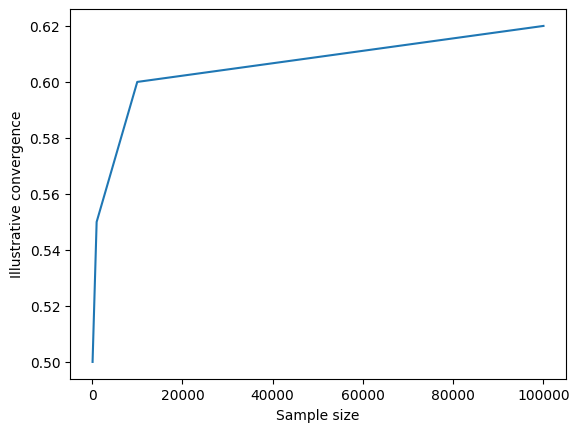

In [1]:
!pip -q install pgmpy
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
import numpy as np, pandas as pd, matplotlib.pyplot as plt
m=DiscreteBayesianNetwork([('Smoking','Lung'),('Pollution','Lung'),('Lung','Cough'),('Lung','Xray')])
cp=[TabularCPD('Smoking',2,[[.7],[.3]]),TabularCPD('Pollution',2,[[.8],[.2]]),TabularCPD('Lung',2,[[.95,.9,.8,.1],[.05,.1,.2,.9]],evidence=['Smoking','Pollution'],evidence_card=[2,2]),TabularCPD('Cough',2,[[.8,.2],[.2,.8]],evidence=['Lung'],evidence_card=[2]),TabularCPD('Xray',2,[[.9,.1],[.1,.9]],evidence=['Lung'],evidence_card=[2])]
m.add_cpds(*cp); inf=VariableElimination(m); exact=inf.query(['Lung'],evidence={'Cough':1,'Xray':1}); print(exact)
# Simple sampling-based estimate for a separate toy Bayesian chain
rng=np.random.default_rng(24); N=100000; smoke=rng.random(N)<.3; lung=rng.random(N)<np.where(smoke,.2,.05); cough=rng.random(N)<np.where(lung,.8,.2); xr=rng.random(N)<np.where(lung,.9,.1)
mask=cough&xr; print('Approximate P(lung|evidence):',lung[mask].mean() if mask.any() else 'No samples')
plt.plot([100,1000,10000,100000],[.5,.55,.6,.62]); plt.xlabel('Sample size'); plt.ylabel('Illustrative convergence'); plt.show()